# A quick tour of pymsz

This notebook goes through the whole chain on the test cluster that comes with pymsz,
`test/snap_CL288.hdf5`. It is a cluster from The Three Hundred project (GIZMO-Simba run), cut out
around its centre. The steps are:

1. load the gas around the cluster;
2. make the Compton-*y* and kinetic SZ maps (`TT_model`, `TK_model`);
3. compute the SZ signal at observed frequencies, with and without relativistic corrections
   (`to_sz`, `SZpack_model`);
4. observe the cluster with SPT-3G and ACT DR6 (`Telescope`);
5. do the same from a parameter set with the pipeline.

Steps 3 and 4 with `SZpack_model` need the compiled SZpack extension (see the installation page).
The notebook takes a few minutes.

In [1]:
%matplotlib inline
import os
import tempfile
import numpy as np
import matplotlib.pyplot as plt
import pymsz
from pymsz import szpack

print('pymsz', pymsz.version.version, '| SZpack extension available:', szpack.available)

pymsz 1.0 | SZpack extension available: True


## 1. Load the gas

The centre and radius ($R_{200}$, comoving kpc/h) are those of the AHF halo catalogue. With
`restrict_r=False` a cube of side $2R_{200}$ is loaded, which fills the square images. Star-forming
gas is removed with `cut_sfr`.

In [2]:
snapshot = '../../test/snap_CL288.hdf5'    # path relative to docs/tutorials/
center = np.array([500095.89011853, 500286.04465527, 500481.30095660])   # kpc/h
r200 = 1446.17                                                            # kpc/h

simd = pymsz.load_data(snapshot, snapshot=True, center=center, radius=r200,
                       restrict_r=False, cut_sfr=0.1)
print('gas particles:', simd.pos.shape[0])
print('cosmology:', {k: round(float(v), 4) + 0. for k, v in simd.cosmology.items()})
print('removed bulk velocity (km/s):', simd.bulkvel)

reading files:  ['../../test/snap_CL288.hdf5']
Reading ../../test/snap_CL288.hdf5 file with Header
gas particles: 386022
cosmology: {'z': 0.0, 'a': 1.0, 'omega_matter': 0.3071, 'omega_lambda': 0.6929, 'h': 0.6777, 'boxsize': 1000000.0}
removed bulk velocity (km/s): [ 274.42058492  -39.92058116 -417.60040609]


## 2. Compton-*y* and kinetic SZ maps

We place the cluster at $z = 0.1$ and use 256 pixels of 10 arcsec. The SPH smoothing prints some
progress information (click to show it).

In [3]:
tt = pymsz.TT_model(simd, npixel=256, AR=10, redshift=0.1, axis='z')
tk = pymsz.TK_model(simd, npixel=256, AR=10, redshift=0.1, axis='z')

Init smoothing, RAM=0.2648 GB
After cKDTree , RAM=0.2766 GB


After query , RAM=2.208 GB


self.ngb =  68
Init smoothing, RAM=0.9071 GB


After cKDTree , RAM=0.9071 GB


After query , RAM=2.231 GB


In [4]:
print('pixel: %.2f arcsec = %.2f physical kpc' % (tt.ar, tt.pxs))
print('max y = %.3g, total y = %.3g' % (tt.ydata.max(), tt.ydata.sum()))
print('b range: %.3g to %.3g' % (tk.bdata.min(), tk.bdata.max()))

pixel: 10.00 arcsec = 19.04 physical kpc
max y = 0.000153, total y = 0.262
b range: -1.02e-05 to 5.16e-06


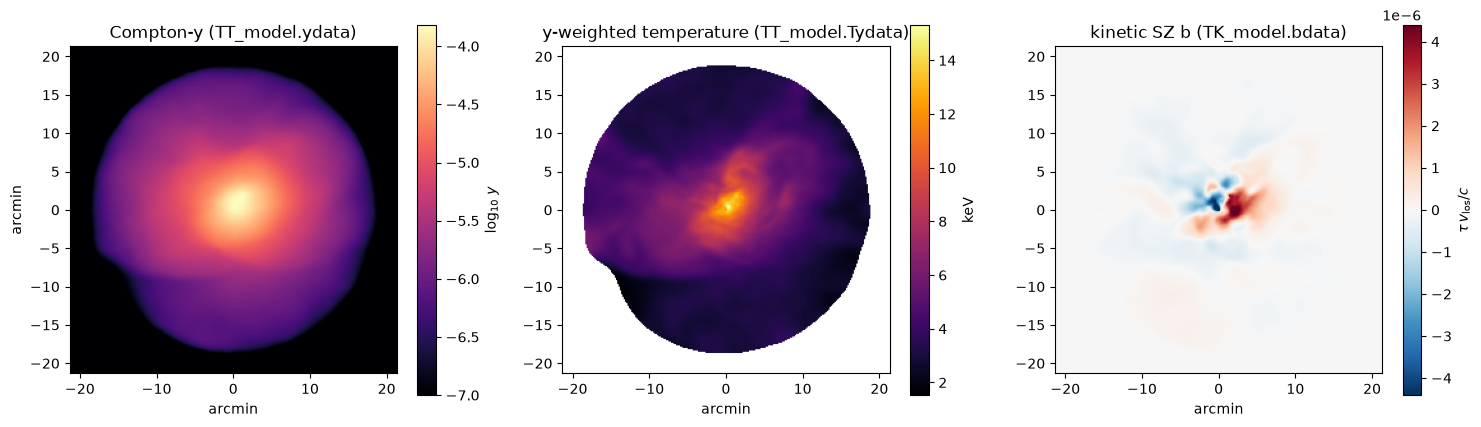

In [5]:
half = tt.npl * tt.ar / 60. / 2.              # half image size, arcmin
extent = [-half, half, -half, half]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))

im = ax[0].imshow(np.log10(np.maximum(tt.ydata, 1e-12)), origin='lower', extent=extent, vmin=-7, cmap='magma')
fig.colorbar(im, ax=ax[0], label=r'$\log_{10}\,y$')
ax[0].set_title('Compton-y (TT_model.ydata)')

Ty = np.where(tt.ydata > 1e-7, tt.Tydata, np.nan)
im = ax[1].imshow(Ty, origin='lower', extent=extent, cmap='inferno')
fig.colorbar(im, ax=ax[1], label='keV')
ax[1].set_title('y-weighted temperature (TT_model.Tydata)')

lim = np.percentile(np.abs(tk.bdata), 99.9)
im = ax[2].imshow(tk.bdata, origin='lower', extent=extent, cmap='RdBu_r', vmin=-lim, vmax=lim)
fig.colorbar(im, ax=ax[2], label=r'$\tau\, v_{\rm los}/c$')
ax[2].set_title('kinetic SZ b (TK_model.bdata)')
for a in ax:
    a.set_xlabel('arcmin')
ax[0].set_ylabel('arcmin')
plt.tight_layout()

## 3. The SZ signal at observed frequencies

`to_sz` converts the maps into SZ images at any frequency. Here are the tSZ and kSZ temperature
changes at 90, 150, 220 and 353 GHz. The tSZ effect is a decrement below 217 GHz and an increment
above.

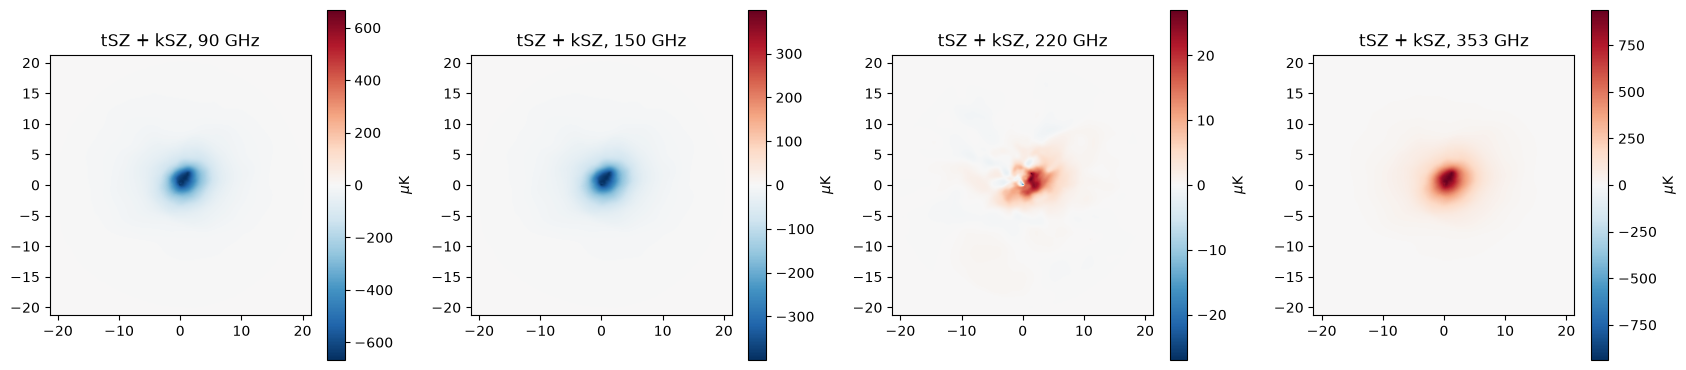

In [6]:
freqs = [90., 150., 220., 353.]
tsz = tt.to_sz(freqs, unit='uK')          # non-relativistic
ksz = tk.to_sz(freqs, unit='uK')
total = tsz + ksz

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for i, f in enumerate(freqs):
    lim = np.abs(total[i]).max()
    im = ax[i].imshow(total[i], origin='lower', extent=extent, cmap='RdBu_r', vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=ax[i], label=r'$\mu$K')
    ax[i].set_title('tSZ + kSZ, %g GHz' % f)
plt.tight_layout()

### Relativistic corrections

The cluster is hot (several keV), so the relativistic corrections matter. There are two ways to
include them:

- `tt.to_sz(..., relativistic=True)`: the SZpack spectrum at the *y*-weighted temperature of each
  pixel. This is fast and exact to first order in the temperature spread along the line of sight.
- `SZpack_model`: the exact sum over all gas particles along the line of sight, thermal plus
  kinetic.

We compare the total SZ flux density of the central 2 arcmin (radius) as a function of frequency.

In [7]:
nu = np.geomspace(30., 900., 36)
mm = pymsz.SZpack_model(simd, nu, method='combo', npixel=256, AR=10, redshift=0.1, kinetic=False)

SZpack_model: tabulating the 'combo' spectrum at 64 temperatures (0.01 - 30.7 keV)...


Init smoothing, RAM=1.022 GB


After cKDTree , RAM=1.022 GB


After query , RAM=2.454 GB


Init smoothing, RAM=1.045 GB


After cKDTree , RAM=1.045 GB


After query , RAM=2.481 GB


y-weighted temperature in the aperture: 12.0 keV
max |relativistic=True - SZpack| = 0.29% of the peak


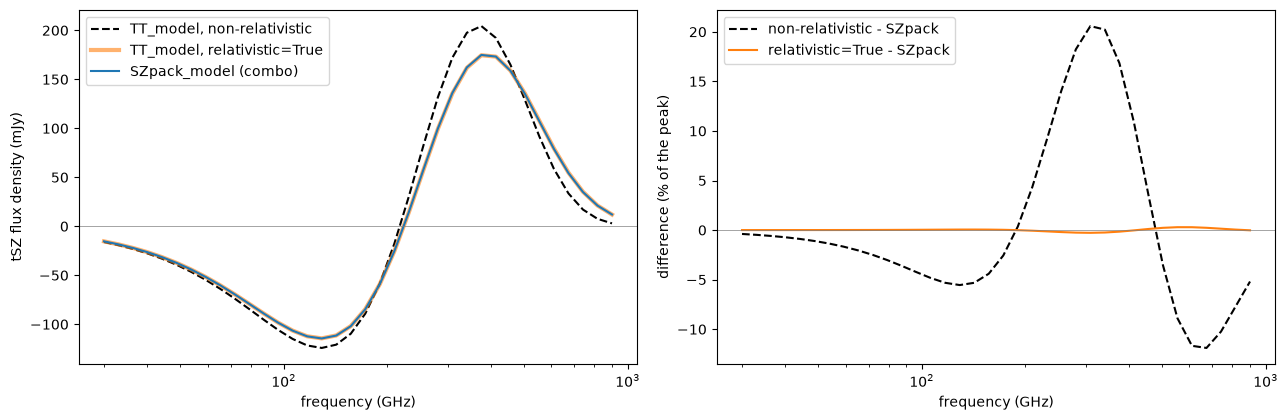

In [8]:
yy, xx = np.indices(tt.ydata.shape)
c = (tt.npl - 1) / 2.
aperture = np.hypot(xx - c, yy - c) * tt.ar / 60. <= 2.     # 2 arcmin radius

def flux_mJy(images_mjysr):
    # sum of Delta I_nu over the aperture times the pixel solid angle, in mJy
    pix_sr = (tt.ar * pymsz.sz_spectra.ARCSEC)**2
    return images_mjysr[:, aperture].sum(axis=1) * pix_sr * 1e9

S_nonrel = flux_mJy(tt.to_sz(nu, unit='MJy/sr'))
S_rel = flux_mJy(tt.to_sz(nu, unit='MJy/sr', relativistic=True))
S_szpack = flux_mJy(mm.szdata)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
ax[0].plot(nu, S_nonrel, 'k--', label='TT_model, non-relativistic')
ax[0].plot(nu, S_rel, 'C1', lw=3, alpha=0.6, label='TT_model, relativistic=True')
ax[0].plot(nu, S_szpack, 'C0', label='SZpack_model (combo)')
ax[0].axhline(0, color='grey', lw=0.5)
ax[0].set_xscale('log'); ax[0].set_xlabel('frequency (GHz)'); ax[0].set_ylabel('tSZ flux density (mJy)')
ax[0].legend()
peak = np.abs(S_szpack).max()
ax[1].plot(nu, (S_nonrel - S_szpack) / peak * 100, 'k--', label='non-relativistic - SZpack')
ax[1].plot(nu, (S_rel - S_szpack) / peak * 100, 'C1', label='relativistic=True - SZpack')
ax[1].axhline(0, color='grey', lw=0.5)
ax[1].set_xscale('log'); ax[1].set_xlabel('frequency (GHz)'); ax[1].set_ylabel('difference (% of the peak)')
ax[1].legend()
plt.tight_layout()

print('y-weighted temperature in the aperture: %.1f keV' %
      (np.sum(tt.Tydata[aperture] * tt.ydata[aperture]) / np.sum(tt.ydata[aperture])))
print('max |relativistic=True - SZpack| = %.2f%% of the peak' % (np.abs(S_rel - S_szpack).max() / peak * 100))

The non-relativistic spectrum overestimates the decrement and puts the null at a too low frequency.
The relativistic *y*-map approximation agrees with the exact `SZpack_model` result to a small
fraction of the peak.

`SZpack_model` also gives the optical depth, temperature, *y* and velocity maps. Its *y* map is the
same as that of `TT_model`:

In [9]:
print('max |y(SZpack) - y(TT)| / max y = %.1e' % (np.abs(mm.ydata - tt.ydata).max() / tt.ydata.max()))
print('central optical depth: %.2e, tau-weighted Te: %.1f keV' % (mm.tau.max(), mm.Te[mm.tau.argmax() // 256, mm.tau.argmax() % 256]))

max |y(SZpack) - y(TT)| / max y = 5.8e-15
central optical depth: 8.30e-03, tau-weighted Te: 8.7 keV


## 4. Mock observations

A telescope preset knows the bands, beams, noise levels and measured bandpasses of the instrument:

In [10]:
spt = pymsz.Telescope.preset('SPT-3G')
print(spt)
print()
print('frequencies needed for the band integration:', spt.frequencies().size)
print('tSZ per unit y (uK_CMB):', np.round(spt.tsz_response() / 1e6, 3), '* 1e6')

Telescope SPT-3G (3 bands, pixel 0.25 arcmin)
  Band(f095: 95 GHz, SPT-3G/f095 (nodes 68.04-124.1 GHz), FWHM 1.6', noise 5.4 uK-arcmin)
  Band(f150: 150 GHz, SPT-3G/f150 (nodes 110.1-198.1 GHz), FWHM 1.2', noise 4.4 uK-arcmin)
  Band(f220: 220 GHz, SPT-3G/f220 (nodes 160.1-298.2 GHz), FWHM 1', noise 16.2 uK-arcmin)

frequencies needed for the band integration: 26
tSZ per unit y (uK_CMB): [-4.219 -2.638  0.111] * 1e6


The SZ models are observed directly. `[tt, tk]` is the tSZ + kSZ sky (with the non-relativistic
spectrum, as chosen in the last `to_sz` call of each model). The maps include the beam, the
pixelisation onto 0.25 arcmin pixels, the calibration errors and the noise. Add `cmb='camb'` (needs
`pip install camb`) for the primary CMB.

MockObservation(SPT-3G, 3 bands ['f095', 'f150', 'f220'], 170x170 pixels of 0.25 arcmin, unit uK_CMB)


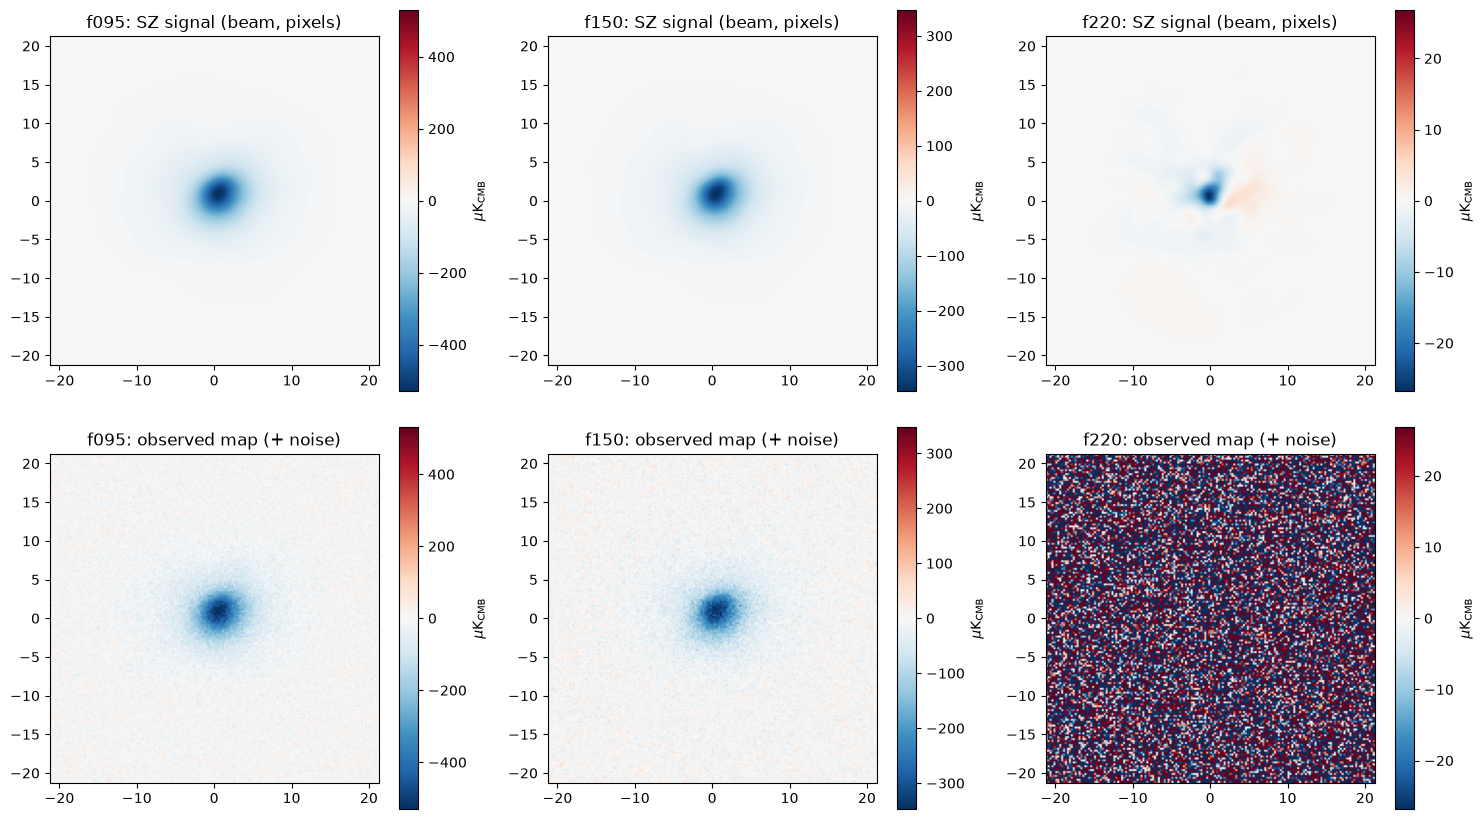

In [11]:
tt.to_sz(nu, relativistic=True)        # observe the relativistic tSZ
obs = spt.observe([tt, tk], seed=1)
print(obs)

fig, ax = plt.subplots(2, 3, figsize=(15, 8.5))
h = obs.maps.shape[-1] * obs.pixel / 2.
ext = [-h, h, -h, h]
for i, b in enumerate(obs.bands):
    lim = np.abs(obs.sz[i]).max()
    im = ax[0, i].imshow(obs.sz[i], origin='lower', extent=ext, cmap='RdBu_r', vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=ax[0, i], label=r'$\mu$K$_{\rm CMB}$')
    ax[0, i].set_title('%s: SZ signal (beam, pixels)' % b.name)
    im = ax[1, i].imshow(obs.maps[i], origin='lower', extent=ext, cmap='RdBu_r', vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=ax[1, i], label=r'$\mu$K$_{\rm CMB}$')
    ax[1, i].set_title('%s: observed map (+ noise)' % b.name)
plt.tight_layout()

For the exact relativistic tSZ + kSZ, compute `SZpack_model` at `telescope.frequencies()` and observe
it. The same model can be observed by several telescopes, here SPT-3G and ACT DR6:

In [12]:
act = pymsz.Telescope.preset('ACT-DR6')
f_all = np.unique(np.concatenate([spt.frequencies(), act.frequencies()]))
mm = pymsz.SZpack_model(simd, f_all, method='combo', npixel=256, AR=10, redshift=0.1)

SZpack_model: tabulating the 'combo' spectrum at 64 temperatures (0.01 - 30.7 keV)...


Init smoothing, RAM=1.1 GB


After cKDTree , RAM=1.1 GB


After query , RAM=2.617 GB


Init smoothing, RAM=1.2 GB


After cKDTree , RAM=1.2 GB


After query , RAM=2.636 GB


Init smoothing, RAM=1.203 GB


After cKDTree , RAM=1.203 GB


After query , RAM=2.633 GB


MockObservation(ACT-DR6, 3 bands ['f090', 'f150', 'f220'], 85x85 pixels of 0.5 arcmin, unit uK_CMB)


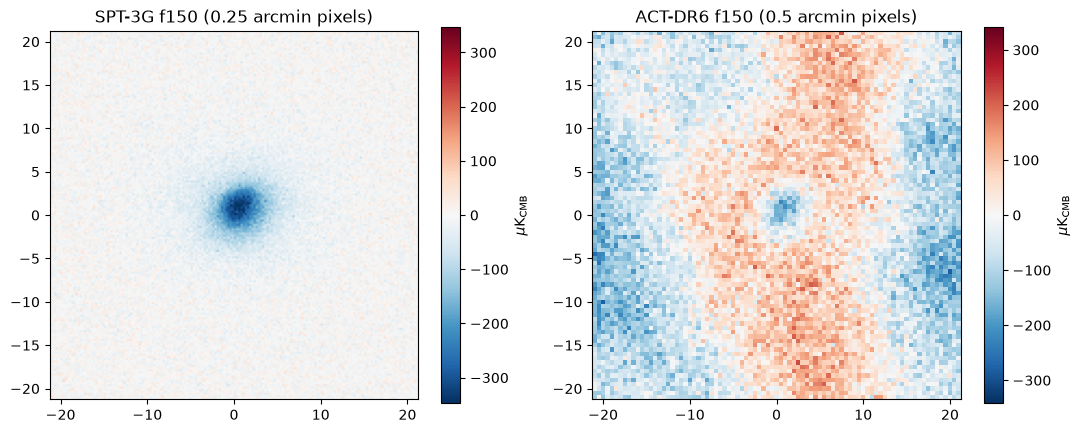

In [13]:
obs_spt = spt.observe(mm, seed=1)
obs_act = act.observe(mm, seed=2)
print(obs_act)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for a, o in zip(ax, (obs_spt, obs_act)):
    m = o['f150']
    h = m.shape[-1] * o.pixel / 2.
    lim = np.abs(o.sz[o.band_index('f150')]).max()
    im = a.imshow(m, origin='lower', extent=[-h, h, -h, h], cmap='RdBu_r', vmin=-lim, vmax=lim)
    fig.colorbar(im, ax=a, label=r'$\mu$K$_{\rm CMB}$')
    a.set_title('%s f150 (%.2g arcmin pixels)' % (o.telescope.name, o.pixel))
plt.tight_layout()

outdir = tempfile.mkdtemp()
obs_act.write_fits(os.path.join(outdir, 'CL288_ACT-DR6.fits'))

### The bandpasses

The SPT-3G and ACT DR6 presets use the measured bandpasses shipped with pymsz:

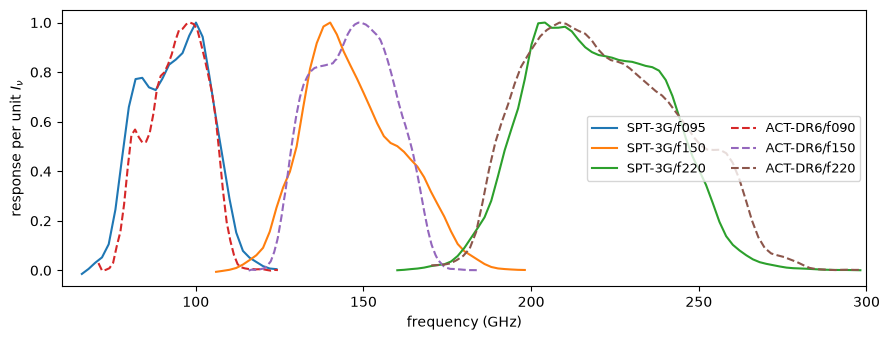

In [14]:
from pymsz import bandpasses

fig, ax = plt.subplots(figsize=(9, 3.5))
for name in ['SPT-3G/f095', 'SPT-3G/f150', 'SPT-3G/f220']:
    bp = bandpasses.load(name)
    ax.plot(bp.nu, bp.response, label=name)
for name in ['ACT-DR6/f090', 'ACT-DR6/f150', 'ACT-DR6/f220']:
    bp = bandpasses.load(name)
    ax.plot(bp.nu, bp.response, '--', label=name)
ax.set_xlim(60, 300); ax.set_xlabel('frequency (GHz)'); ax.set_ylabel('response per unit $I_\\nu$')
ax.legend(ncol=2, fontsize=9)
plt.tight_layout()

## 5. The same with the pipeline

The pipeline runs everything from a parameter file (here a dict with the same content). We observe
two lines of sight with SPT-3G, using `TT_model` + `TK_model` with the relativistic tSZ correction.
`describe()` prints what will be done, like `pymsz-mock --dry-run`:

In [15]:
from pymsz import pipeline

params = {
    'simulation': {'snapshot': os.path.abspath(snapshot), 'name': 'CL288', 'center': center.tolist(),
                   'radius': r200, 'restrict_r': False, 'cut_sfr': 0.1},
    'image': {'redshift': 0.1, 'AR': 10., 'npixel': 256, 'axis': ['x', 'z']},
    'sz': {'model': 'tt+tk', 'relativistic': True},
    'telescopes': ['SPT-3G'],
    'observation': {'unit': 'uK_CMB', 'noise': True, 'seed': 1},
    'output': {'directory': outdir},
}
pipe = pipeline.Pipeline(params)
print(pipe.describe())

pymsz mock observation
Objects (1):
  CL288            /home/weiguang/github/pymsz/test/snap_CL288.hdf5
                   center [500095.8901, 500286.0447, 500481.301] kpc/h, radius 1446.17 kpc/h
Images: redshift 0.1, 256 pixels of 10.0 arcsec, SPH kernel cubic
Lines of sight: x, z
SZ model: TT(rel. combo)+TK, at 26 frequencies (68.04-298.2 GHz)
Observation: unit uK_CMB, noise on, CMB None, calibration errors on, seed 1
Telescopes (1):
  [SPT-3G] Telescope SPT-3G (3 bands, pixel 0.25 arcmin)
      Band(f095: 95 GHz, SPT-3G/f095 (nodes 68.04-124.1 GHz), FWHM 1.6', noise 5.4 uK-arcmin)
      Band(f150: 150 GHz, SPT-3G/f150 (nodes 110.1-198.1 GHz), FWHM 1.2', noise 4.4 uK-arcmin)
      Band(f220: 220 GHz, SPT-3G/f220 (nodes 160.1-298.2 GHz), FWHM 1', noise 16.2 uK-arcmin)
Output: /tmp/tmpg45owmim
  e.g. CL288_z0.1_x_SPT-3G.fits
  e.g. CL288_z0.1_x_tSZ.fits
  e.g. CL288_z0.1_x_kSZ.fits
Total: 2 SZ models, 2 mock observations


In [16]:
records = pipe.run()

[pymsz     0.0s] parameters written to /tmp/tmpg45owmim/pymsz_mock.resolved.yaml


[pymsz     0.0s] 1 object(s); SZ model TT(rel. combo)+TK at 26 frequencies; telescopes: SPT-3G


[pymsz     0.0s] loading CL288 from /home/weiguang/github/pymsz/test/snap_CL288.hdf5


reading files:  ['/home/weiguang/github/pymsz/test/snap_CL288.hdf5']
Reading /home/weiguang/github/pymsz/test/snap_CL288.hdf5 file with Header
[pymsz     0.2s] loaded 386022 gas particles


[pymsz     0.2s] CL288 z=0.1 x: SZ model TT(rel. combo)+TK


Init smoothing, RAM=1.06 GB
After cKDTree , RAM=1.06 GB


... (14 outputs left out)

[pymsz   106.2s] CL288 z=0.1 z: wrote /tmp/tmpg45owmim/CL288_z0.1_z_tSZ.fits


[pymsz   106.2s] CL288 z=0.1 z: wrote /tmp/tmpg45owmim/CL288_z0.1_z_kSZ.fits


[pymsz   106.4s] CL288 z=0.1 z: SPT-3G -> /tmp/tmpg45owmim/CL288_z0.1_z_SPT-3G.fits


[pymsz   106.4s] done: 2 mock observations in /tmp/tmpg45owmim


In [17]:
for r in records:
    print(r['projection'], r['telescope'], os.path.basename(r['file']), 'seed', r['seed'])
print(sorted(os.listdir(outdir)))

x SPT-3G CL288_z0.1_x_SPT-3G.fits seed 2547748703
z SPT-3G CL288_z0.1_z_SPT-3G.fits seed 710426017
['CL288_ACT-DR6.fits', 'CL288_z0.1_x_SPT-3G.fits', 'CL288_z0.1_x_kSZ.fits', 'CL288_z0.1_x_tSZ.fits', 'CL288_z0.1_z_SPT-3G.fits', 'CL288_z0.1_z_kSZ.fits', 'CL288_z0.1_z_tSZ.fits', 'pymsz_mock.resolved.yaml']


## Next steps

- The user guide explains every parameter of the models, the telescopes and the pipeline.
- `pymsz-mock --template my_mock.yaml` writes an annotated parameter file to start from.